## 1. Setup and load

### 1.1 Install libraries and connect Drive

In [1]:
!pip install -q xgboost shap fairlearn

from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 1.2 Download Strategic Subject List (SSL) Data

In [2]:
from pathlib import Path
import requests

project_dir = Path("/content/drive/MyDrive/ds680_ssl")
raw_dir = project_dir / "data"
raw_dir.mkdir(parents=True, exist_ok=True)

ssl_url = "https://data.cityofchicago.org/api/views/4aki-r3np/rows.csv?accessType=DOWNLOAD"
ssl_csv = raw_dir / "ssl.csv"

if not ssl_csv.exists():
    try:
        with requests.get(ssl_url, stream=True, timeout=60) as response:
            response.raise_for_status()
            with open(ssl_csv, "wb") as out_file:
                for chunk in response.iter_content(chunk_size=1 << 20):
                    out_file.write(chunk)
    except requests.exceptions.Timeout:
        ssl_csv.unlink(missing_ok=True)
        raise RuntimeError("Portal timed out. Rerun this cell, or download the CSV manually into the data folder.")
    except requests.exceptions.HTTPError as http_err:
        ssl_csv.unlink(missing_ok=True)
        raise RuntimeError(f"Portal returned an error: {http_err}")
    except requests.exceptions.ConnectionError:
        ssl_csv.unlink(missing_ok=True)
        raise RuntimeError("No connection to the portal. Check Colab's internet and rerun.")

print(f"{ssl_csv.stat().st_size / 1e6:.1f} MB")

71.9 MB


### 1.3 Load and inspect raw data

In [3]:
import pandas as pd

pd.set_option("display.width", 200)

try:
    ssl_raw = pd.read_csv(ssl_csv, low_memory=False)
except pd.errors.EmptyDataError:
    raise RuntimeError("ssl.csv is empty. Delete it and rerun the download cell.")
except pd.errors.ParserError as parse_err:
    raise RuntimeError(f"ssl.csv looks corrupted (partial download?): {parse_err}")

print(ssl_raw.shape)
print(ssl_raw.columns.tolist())
print(ssl_raw.dtypes)
print(ssl_raw.isna().sum().sort_values(ascending=False))

(398684, 48)
['SSL SCORE', 'PREDICTOR RAT AGE AT LATEST ARREST', 'PREDICTOR RAT VICTIM SHOOTING INCIDENTS', 'PREDICTOR RAT VICTIM BATTERY OR ASSAULT', 'PREDICTOR RAT ARRESTS VIOLENT OFFENSES', 'PREDICTOR RAT GANG AFFILIATION', 'PREDICTOR RAT NARCOTIC ARRESTS', 'PREDICTOR RAT TREND IN CRIMINAL ACTIVITY', 'PREDICTOR RAT UUW ARRESTS', 'SEX CODE CD', 'RACE CODE CD', 'WEAPON I', 'DRUG I', 'AGE GROUP', 'AGE TO', 'STOP ORDER NO', 'PAROLEE I', 'LATEST DATE', 'LATEST DIST', 'MAJORITY DIST', 'DLST', 'LATEST DIST RES', 'WEAPONS ARR CNT', 'LATEST WEAPON ARR DATE', 'NARCOTICS ARR CNT', 'LATEST NARCOTIC ARR DATE', 'IDOC RES CITY', 'IDOC RES STATE CODE', 'IDOC RES ZIP CODE', 'IDOC CPD DIST', 'CPD ARREST I', 'DOMESTIC ARR CNT', 'LATEST DOMESTIC ARR DATE', 'AGE CURR', 'SSL LAST PTV DATE', 'TRAP STATUS', 'RAW SSL SCORE', 'HEAT SCORE', 'RAW_HEAT_SCORE', 'STATUS I', 'PRE RAW HEAT SCORE', 'TRAP FLAGS', 'SSL FLAGS', 'LATITUDE', 'LONGITUDE', 'CENSUS TRACT', 'COMMUNITY AREA', 'LOCATION']
SSL SCORE            

## 2. Clean the Data

### 2.1 Select and rename columns

In [4]:
column_names = {
    "SSL SCORE": "ssl_score",
    "PREDICTOR RAT AGE AT LATEST ARREST": "age_at_arrest",
    "PREDICTOR RAT VICTIM SHOOTING INCIDENTS": "victim_shooting",
    "PREDICTOR RAT VICTIM BATTERY OR ASSAULT": "victim_battery",
    "PREDICTOR RAT ARRESTS VIOLENT OFFENSES": "violent_arrests",
    "PREDICTOR RAT GANG AFFILIATION": "gang_affiliation",
    "PREDICTOR RAT NARCOTIC ARRESTS": "narcotic_arrests",
    "PREDICTOR RAT TREND IN CRIMINAL ACTIVITY": "crime_trend",
    "PREDICTOR RAT UUW ARRESTS": "weapon_arrests",
    "SEX CODE CD": "sex_code",
    "RACE CODE CD": "race_code",
    "COMMUNITY AREA": "community_area",
    "LATEST DIST": "police_district",
}

missing_cols = set(column_names) - set(ssl_raw.columns)
if missing_cols:
    raise KeyError(f"Expected columns not found: {missing_cols}")

ssl = ssl_raw[list(column_names)].rename(columns=column_names).copy()
row_log = {"raw": len(ssl)}

print(ssl.shape)
print(ssl.head())

(398684, 13)
   ssl_score age_at_arrest  victim_shooting  victim_battery  violent_arrests  gang_affiliation  narcotic_arrests  crime_trend  weapon_arrests sex_code race_code community_area  police_district
0        306         20-30                0               0                0                 0                 0         -0.3               0        M       WWH                              31
1        352         20-30                0               1                0                 0                 0          0.0               0        M       BLK                              31
2        349         20-30                0               0                2                 0                 2          0.0               0        M       BLK                              31
3        344         20-30                0               0                3                 0                 0         -0.3               0        M       WHI                              31
4        343         2

### 2.2 Race, sex, and age groups

In [5]:
race_labels = {"BLK": "Black", "WHI": "White", "WWH": "Hispanic", "WBH": "Hispanic", "API": "Asian/Pacific Islander"}
ssl["race"] = ssl["race_code"].str.strip().map(race_labels).fillna("Other")

sex_labels = {"M": "Male", "F": "Female"}
ssl["sex"] = ssl["sex_code"].str.strip().map(sex_labels).fillna("Unknown")

ssl = ssl.dropna(subset=["age_at_arrest"])
row_log["after_age_drop"] = len(ssl)

age_text = ssl["age_at_arrest"].astype(str).str.strip().str.lower()
age_floor = age_text.str.extract(r"(\d+)")[0].astype(float)
age_floor[age_text.str.startswith("less")] = 0

age_order = (
    pd.DataFrame({"band": ssl["age_at_arrest"].astype(str), "floor": age_floor})
    .groupby("band")["floor"].min()
    .sort_values()
    .index.tolist()
)
ssl["age_at_arrest"] = pd.Categorical(ssl["age_at_arrest"].astype(str), categories=age_order, ordered=True)
ssl["age_rank"] = ssl["age_at_arrest"].cat.codes

print(row_log)
print(ssl["race"].value_counts(), "\n")
print(ssl["sex"].value_counts(), "\n")
print(ssl["age_at_arrest"].value_counts(sort=False))

{'raw': 398684, 'after_age_drop': 398582}
race
Black                     207800
Hispanic                  101671
White                      82323
Asian/Pacific Islander      4614
Other                       2174
Name: count, dtype: int64 

sex
Male       302230
Female      96295
Unknown        57
Name: count, dtype: int64 

age_at_arrest
less than 20     66631
20-30           140357
30-40            89165
40-50            59082
50-60            34528
60-70             7824
70-80              995
Name: count, dtype: int64


### 2.3 Community area and flag columns

In [6]:
ssl["community_area"] = ssl["community_area"].astype(str).str.strip().str.upper()
ssl.loc[ssl["community_area"].isin(["", "NAN", "NONE"]), "community_area"] = pd.NA

ssl["flag_250"] = (ssl["ssl_score"] >= 250).astype(int)
ssl["flag_480"] = (ssl["ssl_score"] >= 480).astype(int)

life_event_inputs = ["age_rank", "victim_shooting", "victim_battery"]
police_inputs = ["violent_arrests", "gang_affiliation", "narcotic_arrests", "crime_trend", "weapon_arrests"]

print(f"Community area missing: {ssl['community_area'].isna().mean():.1%}")
print(f"Unique community areas: {ssl['community_area'].nunique()}")
print(ssl[["flag_250", "flag_480"]].mean().round(3))
print(ssl["ssl_score"].describe().round(1))

Community area missing: 43.7%
Unique community areas: 77
flag_250    0.721
flag_480    0.001
dtype: float64
count    398582.0
mean        279.9
std          57.9
min          53.0
25%         242.0
50%         289.0
75%         322.0
max         500.0
Name: ssl_score, dtype: float64


### 2.4 Missing community area by race

In [7]:
area_missing_by_race = (
    ssl.assign(area_missing=ssl["community_area"].isna())
    .groupby("race")["area_missing"]
    .agg(["mean", "size"])
    .rename(columns={"mean": "share_missing", "size": "people"})
    .sort_values("share_missing", ascending=False)
)
area_missing_by_race["share_missing"] = area_missing_by_race["share_missing"].round(3)
print(area_missing_by_race)

score_by_area_status = ssl.groupby(ssl["community_area"].isna())["ssl_score"].mean().round(1)
score_by_area_status.index = ["has area", "missing area"]
print("\n", score_by_area_status)

                        share_missing  people
race                                         
White                           0.671   82323
Other                           0.666    2174
Asian/Pacific Islander          0.566    4614
Hispanic                        0.503  101671
Black                           0.307  207800

 has area        283.0
missing area    275.9
Name: ssl_score, dtype: float64


### 2.5 Save clean data

In [8]:
clean_path = raw_dir / "ssl_clean.parquet"

try:
    ssl.to_parquet(clean_path, index=False)
except ImportError:
    clean_path = raw_dir / "ssl_clean.csv"
    ssl.to_csv(clean_path, index=False)
except OSError as save_err:
    raise SystemExit(f"Could not save to {clean_path}: {save_err}")

print(f"Saved {len(ssl):,} rows to {clean_path}")
print(f"{clean_path.stat().st_size / 1e6:.1f} MB")

Saved 398,582 rows to /content/drive/MyDrive/ds680_ssl/data/ssl_clean.parquet
2.0 MB


## 3. Who gets scored?

### 3.1 SSL vs Chicago population by race

In [9]:
import matplotlib.pyplot as plt
import numpy as np

figures_dir = project_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

chicago_2010_share = {
    "Black": 0.329,
    "Hispanic": 0.289,
    "White": 0.317,
    "Asian/Pacific Islander": 0.055,
}
compared_groups = list(chicago_2010_share)

ssl_share = ssl["race"].value_counts(normalize=True).reindex(compared_groups)

representation = pd.DataFrame({
    "ssl_share": ssl_share,
    "chicago_share": pd.Series(chicago_2010_share),
})
representation["ratio"] = representation["ssl_share"] / representation["chicago_share"]
print(representation.round(3))

                        ssl_share  chicago_share  ratio
Black                       0.521          0.329  1.585
Hispanic                    0.255          0.289  0.883
White                       0.207          0.317  0.652
Asian/Pacific Islander      0.012          0.055  0.210


### 3.2 Figure 1

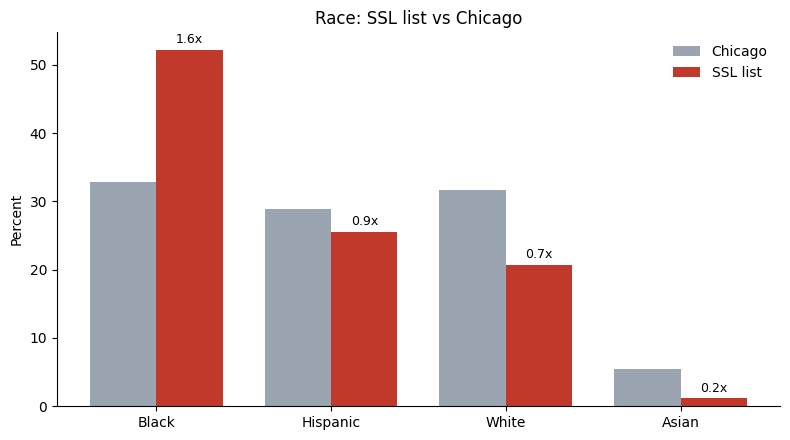

In [10]:
bar_positions = np.arange(len(compared_groups))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(bar_positions - bar_width / 2, representation["chicago_share"] * 100, bar_width, label="Chicago", color="#9aa5b1")
ax.bar(bar_positions + bar_width / 2, representation["ssl_share"] * 100, bar_width, label="SSL list", color="#c0392b")

for pos, ratio_value in zip(bar_positions, representation["ratio"]):
    ax.text(pos + bar_width / 2, representation["ssl_share"].iloc[pos] * 100 + 1, f"{ratio_value:.1f}x", ha="center", fontsize=9)

ax.set_xticks(bar_positions)
ax.set_xticklabels(["Black", "Hispanic", "White", "Asian"])
ax.set_ylabel("Percent")
ax.set_title("Race: SSL list vs Chicago")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

fig.savefig(figures_dir / "fig1_representation.png", dpi=200)
plt.show()

## 4. Score gaps by group

### 4.1 Scores and flag rates by group

In [11]:
main_groups = ["Black", "Hispanic", "White"]
main_ssl = ssl[ssl["race"].isin(main_groups)]

def group_summary(frame, group_col):
    summary = frame.groupby(group_col, observed=True).agg(
        people=("ssl_score", "size"),
        mean_score=("ssl_score", "mean"),
        median_score=("ssl_score", "median"),
        flag_250_rate=("flag_250", "mean"),
        flag_480_rate=("flag_480", "mean"),
    )
    return summary.round(3)

race_summary = group_summary(main_ssl, "race")
race_summary["flag_ratio_vs_white"] = (race_summary["flag_250_rate"] / race_summary.loc["White", "flag_250_rate"]).round(2)

print(race_summary, "\n")
print(group_summary(ssl[ssl["sex"] != "Unknown"], "sex"), "\n")
print(group_summary(ssl, "age_at_arrest"))

          people  mean_score  median_score  flag_250_rate  flag_480_rate  flag_ratio_vs_white
race                                                                                         
Black     207800     282.474         293.0          0.718          0.001                 1.06
Hispanic  101671     283.340         289.0          0.765          0.000                 1.13
White      82323     269.844         283.0          0.679          0.000                 1.00 

        people  mean_score  median_score  flag_250_rate  flag_480_rate
sex                                                                   
Female   96295     283.490         295.0          0.754          0.000
Male    302230     278.759         288.0          0.711          0.001 

               people  mean_score  median_score  flag_250_rate  flag_480_rate
age_at_arrest                                                                
less than 20    66631     347.975         342.0          1.000          0.004
20-30   

### 4.2 Tests and city-wide flag rates

In [12]:
from scipy import stats

flag_table = pd.crosstab(main_ssl["race"], main_ssl["flag_250"])
chi2_value, p_value, dof, _ = stats.chi2_contingency(flag_table)
cramers_v = np.sqrt(chi2_value / (flag_table.values.sum() * (min(flag_table.shape) - 1)))
print(f"Chi-square: {chi2_value:,.0f}, p = {p_value:.3g}, Cramer's V = {cramers_v:.3f}")

black_scores = main_ssl.loc[main_ssl["race"] == "Black", "ssl_score"]
white_scores = main_ssl.loc[main_ssl["race"] == "White", "ssl_score"]
pooled_sd = np.sqrt((black_scores.var(ddof=1) + white_scores.var(ddof=1)) / 2)
cohens_d = (black_scores.mean() - white_scores.mean()) / pooled_sd
mw_test = stats.mannwhitneyu(black_scores, white_scores, alternative="two-sided")
print(f"Black vs White score: Cohen's d = {cohens_d:.2f}, Mann-Whitney p = {mw_test.pvalue:.3g}\n")

chicago_pop_2010 = 2_695_598
citywide = pd.DataFrame({
    "flagged_people": main_ssl.groupby("race")["flag_250"].sum(),
    "city_population": pd.Series(chicago_2010_share)[main_groups] * chicago_pop_2010,
})
citywide["flagged_per_100_residents"] = citywide["flagged_people"] / citywide["city_population"] * 100
citywide["ratio_vs_white"] = citywide["flagged_per_100_residents"] / citywide.loc["White", "flagged_per_100_residents"]
print(citywide.round(2))

Chi-square: 1,696, p = 0, Cramer's V = 0.066
Black vs White score: Cohen's d = 0.21, Mann-Whitney p = 0

          flagged_people  city_population  flagged_per_100_residents  ratio_vs_white
Black             149133        886851.74                      16.82            2.57
Hispanic           77730        779027.82                       9.98            1.53
White              55890        854504.57                       6.54            1.00


### 4.3 Flagged with no violence on record

In [13]:
no_violent_arrest = (main_ssl["violent_arrests"] == 0) & (main_ssl["weapon_arrests"] == 0)
no_violence_at_all = no_violent_arrest & (main_ssl["victim_shooting"] == 0) & (main_ssl["victim_battery"] == 0)

flagged_only = main_ssl[main_ssl["flag_250"] == 1].assign(
    no_violent_arrest=no_violent_arrest,
    no_violence_at_all=no_violence_at_all,
)

no_violence_summary = flagged_only.groupby("race").agg(
    flagged_people=("flag_250", "size"),
    share_no_violent_arrest=("no_violent_arrest", "mean"),
    share_no_violence_at_all=("no_violence_at_all", "mean"),
    count_no_violence_at_all=("no_violence_at_all", "sum"),
)
no_violence_summary["no_violence_flagged_per_100_residents"] = (
    no_violence_summary["count_no_violence_at_all"]
    / (pd.Series(chicago_2010_share)[main_groups] * chicago_pop_2010) * 100
)

print(f"All flagged people: {len(flagged_only):,}")
print(f"Never arrested for violence or weapons: {flagged_only['no_violent_arrest'].mean():.1%}")
print(f"No violence at all (no violent or weapon arrest, never a victim): {flagged_only['no_violence_at_all'].mean():.1%}\n")
print(no_violence_summary.round(3))

All flagged people: 282,753
Never arrested for violence or weapons: 88.2%
No violence at all (no violent or weapon arrest, never a victim): 84.6%

          flagged_people  share_no_violent_arrest  share_no_violence_at_all  count_no_violence_at_all  no_violence_flagged_per_100_residents
race                                                                                                                                        
Black             149133                    0.834                     0.781                    116479                                 13.134
Hispanic           77730                    0.925                     0.901                     70002                                  8.986
White              55890                    0.951                     0.941                     52611                                  6.157


## 5. Same record, same score?

### 5.1 Flag rates by race within each age group

In [14]:
flag_by_age_race = main_ssl.pivot_table(
    index="age_at_arrest", columns="race", values="flag_250", aggfunc="mean", observed=True
).round(3)

score_by_age_race = main_ssl.pivot_table(
    index="age_at_arrest", columns="race", values="ssl_score", aggfunc="mean", observed=True
).round(1)

print("Flag rate (250+) by age and race")
print(flag_by_age_race, "\n")
print("Average score by age and race")
print(score_by_age_race)

Flag rate (250+) by age and race
race           Black  Hispanic  White
age_at_arrest                        
less than 20   1.000     1.000  1.000
20-30          1.000     1.000  1.000
30-40          0.885     0.852  0.869
40-50          0.062     0.027  0.026
50-60          0.005     0.001  0.001
60-70          0.000     0.000  0.000
70-80          0.000     0.000  0.000 

Average score by age and race
race           Black  Hispanic  White
age_at_arrest                        
less than 20   352.4     344.2  338.7
20-30          315.8     309.4  308.1
30-40          270.0     265.7  266.9
40-50          224.1     224.0  221.2
50-60          182.3     180.5  179.4
60-70          140.2     137.7  136.6
70-80           92.8      91.9   90.1


### 5.2 People with identical records

In [15]:
record_cols = ["age_rank", "victim_shooting", "victim_battery", "violent_arrests",
               "gang_affiliation", "narcotic_arrests", "crime_trend", "weapon_arrests"]

black_white = main_ssl[main_ssl["race"].isin(["Black", "White"])]

record_scores = (
    black_white.groupby(record_cols + ["race"], observed=True)["ssl_score"]
    .agg(["mean", "size"])
    .unstack("race")
)
matched_records = record_scores.dropna(subset=[("mean", "Black"), ("mean", "White")])

score_gap = matched_records[("mean", "Black")] - matched_records[("mean", "White")]
people_in_match = matched_records[("size", "Black")] + matched_records[("size", "White")]

print(f"Matched record types: {len(matched_records):,}")
print(f"Share of Black + White people covered: {people_in_match.sum() / len(black_white):.1%}")
print(f"Average score gap with identical records (Black minus White): {np.average(score_gap, weights=people_in_match):.2f} points")
print(f"Raw score gap (no matching): {black_scores.mean() - white_scores.mean():.2f} points")

Matched record types: 2,078
Share of Black + White people covered: 92.1%
Average score gap with identical records (Black minus White): 1.00 points
Raw score gap (no matching): 12.63 points


## 6. What drives the score?

### 6.1 Rebuild the score with XGBoost

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
from xgboost import XGBRegressor

feature_cols = record_cols

model_frame = ssl[feature_cols + ["ssl_score", "race"]].copy()
X_train, X_test, y_train, y_test, race_train, race_test = train_test_split(
    model_frame[feature_cols], model_frame["ssl_score"], model_frame["race"],
    test_size=0.2, random_state=42,
)

linear_model = LinearRegression().fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

xgb_model = XGBRegressor(
    n_estimators=400, max_depth=6, learning_rate=0.1,
    tree_method="hist", n_jobs=-1, random_state=42,
)
xgb_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
xgb_pred = xgb_model.predict(X_test)

model_scores = pd.DataFrame({
    "R2": [r2_score(y_test, linear_pred), r2_score(y_test, xgb_pred)],
    "MAE (points)": [mean_absolute_error(y_test, linear_pred), mean_absolute_error(y_test, xgb_pred)],
}, index=["Linear regression", "XGBoost"]).round(3)
print(model_scores, "\n")

linear_coefs = pd.Series(linear_model.coef_, index=feature_cols).sort_values(key=abs, ascending=False).round(1)
print("Linear regression: points added per unit of each input")
print(linear_coefs)

                      R2  MAE (points)
Linear regression  0.950        10.773
XGBoost            0.954        10.205 

Linear regression: points added per unit of each input
age_rank           -40.9
victim_battery      33.5
victim_shooting     16.9
violent_arrests     14.9
crime_trend         14.1
weapon_arrests      11.7
narcotic_arrests     5.2
gang_affiliation     4.1
dtype: float64


### 6.2 Which inputs drive the racial gap (SHAP)

In [17]:
import shap

shap_explainer = shap.TreeExplainer(xgb_model)

test_frame = X_test.assign(race=race_test.values)
shap_sample = pd.concat([
    test_frame[test_frame["race"] == group_name].sample(
        n=min(15000, (test_frame["race"] == group_name).sum()), random_state=42
    )
    for group_name in main_groups
])

shap_values = shap_explainer.shap_values(shap_sample[feature_cols])
shap_frame = pd.DataFrame(shap_values, columns=feature_cols, index=shap_sample.index)

mean_shap = shap_frame.groupby(shap_sample["race"]).mean().T
mean_shap["black_minus_white"] = mean_shap["Black"] - mean_shap["White"]

input_type = {col_name: "Life event" for col_name in life_event_inputs}
input_type.update({col_name: "Police decision" for col_name in police_inputs})
mean_shap["input_type"] = mean_shap.index.map(input_type)

print(mean_shap.round(2).sort_values("black_minus_white", ascending=False), "\n")
print(mean_shap.groupby("input_type")["black_minus_white"].sum().round(2))
print(f"\nTotal gap explained: {mean_shap['black_minus_white'].sum():.2f} points")

race              Black  Hispanic  White  black_minus_white       input_type
age_rank          -0.66      5.27  -6.62               5.96       Life event
violent_arrests    0.75     -0.71  -1.02               1.77  Police decision
victim_battery     0.58     -0.28  -0.89               1.47       Life event
narcotic_arrests   0.55     -0.64  -0.53               1.08  Police decision
gang_affiliation   0.29     -0.08  -0.45               0.73  Police decision
victim_shooting    0.14     -0.17  -0.30               0.43       Life event
weapon_arrests     0.06     -0.17  -0.25               0.32  Police decision
crime_trend       -0.17     -0.14   0.23              -0.40  Police decision 

input_type
Life event         7.87
Police decision    3.49
Name: black_minus_white, dtype: float32

Total gap explained: 11.36 points


### 6.3 Figure 2

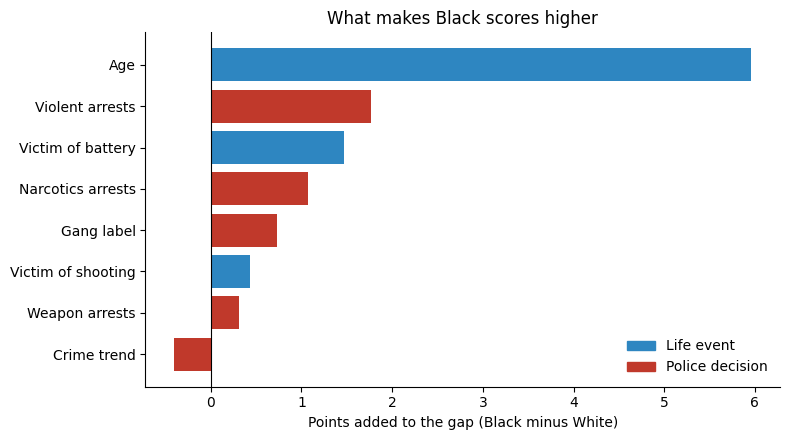

In [18]:
gap_plot = mean_shap.sort_values("black_minus_white")
type_colors = {"Life event": "#2e86c1", "Police decision": "#c0392b"}

nice_names = {
    "age_rank": "Age",
    "violent_arrests": "Violent arrests",
    "victim_battery": "Victim of battery",
    "narcotic_arrests": "Narcotics arrests",
    "gang_affiliation": "Gang label",
    "victim_shooting": "Victim of shooting",
    "weapon_arrests": "Weapon arrests",
    "crime_trend": "Crime trend",
}

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(
    [nice_names[col_name] for col_name in gap_plot.index],
    gap_plot["black_minus_white"],
    color=gap_plot["input_type"].map(type_colors),
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Points added to the gap (Black minus White)")
ax.set_title("What makes Black scores higher")

legend_handles = [plt.Rectangle((0, 0), 1, 1, color=color_value) for color_value in type_colors.values()]
ax.legend(legend_handles, type_colors.keys(), frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

fig.savefig(figures_dir / "fig2_shap_gap.png", dpi=200)
plt.show()

## 7. Neighborhood map

### 7.1 Download boundaries and Census data

In [19]:
for leftover in [raw_dir / "community_area_boundaries.csv", raw_dir / "community_area_acs.csv"]:
    if leftover.exists() and leftover.stat().st_size < 1000:
        leftover.unlink()
        print(f"Removed empty file: {leftover.name}")

In [20]:
import time

retry_codes = {429, 500, 502, 503, 504}

for leftover in [raw_dir / "community_area_boundaries.csv", raw_dir / "community_area_acs.csv"]:
    if leftover.exists() and leftover.stat().st_size < 1000:
        leftover.unlink()
        print(f"Removed empty file: {leftover.name}")

def download_csv(urls, save_path, max_tries=4):
    if save_path.exists():
        return save_path
    last_problem = None
    for url in urls:
        for attempt in range(1, max_tries + 1):
            try:
                with requests.get(url, stream=True, timeout=90) as response:
                    if response.status_code in retry_codes:
                        last_problem = f"{response.status_code} from {url}"
                        time.sleep(5 * attempt)
                        continue
                    response.raise_for_status()
                    with open(save_path, "wb") as out_file:
                        for chunk in response.iter_content(chunk_size=1 << 20):
                            out_file.write(chunk)
                if save_path.stat().st_size < 1000:
                    save_path.unlink()
                    last_problem = f"empty file from {url}"
                    time.sleep(5 * attempt)
                    continue
                return save_path
            except requests.exceptions.Timeout:
                last_problem = f"timeout from {url}"
                save_path.unlink(missing_ok=True)
                time.sleep(5 * attempt)
            except requests.exceptions.ConnectionError:
                last_problem = f"connection failed for {url}"
                save_path.unlink(missing_ok=True)
                time.sleep(5 * attempt)
    raise RuntimeError(
        f"Could not download {save_path.name} ({last_problem}). "
        f"Download it manually from the portal and save it as {save_path}"
    )

area_shapes_csv = download_csv(
    [
        "https://data.cityofchicago.org/api/views/igwz-8jzy/rows.csv?accessType=DOWNLOAD",
        "https://data.cityofchicago.org/api/views/cauq-8yn6/rows.csv?accessType=DOWNLOAD",
    ],
    raw_dir / "community_area_boundaries.csv",
)
area_acs_csv = download_csv(
    ["https://data.cityofchicago.org/api/views/t68z-cikk/rows.csv?accessType=DOWNLOAD"],
    raw_dir / "community_area_acs.csv",
)

area_shapes_raw = pd.read_csv(area_shapes_csv)
area_acs_raw = pd.read_csv(area_acs_csv)

print("Boundaries:", area_shapes_raw.shape)
print(area_shapes_raw.columns.tolist(), "\n")
print("ACS:", area_acs_raw.shape)
print(area_acs_raw.columns.tolist(), "\n")
print(area_acs_raw.head(3).T)

Boundaries: (77, 6)
['the_geom', 'AREA_NUMBE', 'COMMUNITY', 'AREA_NUM_1', 'SHAPE_AREA', 'SHAPE_LEN'] 

ACS: (77, 30)
['ACS Year', 'Community Area', 'Under $25,000', '$25,000 to $49,999', '$50,000 to $74,999', '$75,000 to $125,000', '$125,000 +', 'Male 0 to 17', 'Male 18 to 24', 'Male 25 to 34', 'Male 35 to 49', 'Male 50 to 64', 'Male 65+', 'Female 0 to 17', 'Female 18 to 24', 'Female 25 to 34', 'Female 35 to 49', 'Female 50 to 64', 'Female 65 +', 'Total Population', 'White', 'Black or African American', 'American Indian or Alaska Native', 'Asian', 'Native Hawaiian or Pacific Islander', 'Other Race', 'Multiracial', 'White Not Hispanic or Latino', 'Hispanic or Latino', 'Record ID'] 

                                                    0                    1                   2
ACS Year                                         2023                 2023                2023
Community Area                            ALBANY PARK       ARCHER HEIGHTS       ARMOUR SQUARE
Under $25,000           

### 7.2 ACS 2012 to 2016 by community area

In [21]:
from google.colab import userdata

try:
    census_key = userdata.get("CENSUS_API_KEY")
except userdata.SecretNotFoundError:
    raise RuntimeError("Add CENSUS_API_KEY in Colab Secrets (key icon on the left) and turn on notebook access.")
except userdata.NotebookAccessError:
    raise RuntimeError("Turn on notebook access for CENSUS_API_KEY in Colab Secrets.")

acs_vars = {
    "B02001_001E": "total_pop",
    "B02001_003E": "black_pop",
    "B19001_001E": "households",
    "B19001_002E": "hh_under_10k",
    "B19001_003E": "hh_10k_15k",
    "B19001_004E": "hh_15k_20k",
    "B19001_005E": "hh_20k_25k",
}
acs_tract_csv = raw_dir / "acs2016_cook_tracts.csv"

if not acs_tract_csv.exists():
    census_params = {"get": ",".join(acs_vars), "for": "tract:*", "in": "state:17 county:031", "key": census_key}
    last_census_problem = None
    for attempt in range(1, 5):
        try:
            census_response = requests.get("https://api.census.gov/data/2016/acs/acs5", params=census_params, timeout=90)
        except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as net_err:
            last_census_problem = str(net_err)
            time.sleep(5 * attempt)
            continue
        if census_response.status_code in retry_codes:
            last_census_problem = f"status {census_response.status_code}"
            time.sleep(5 * attempt)
            continue
        if "Missing Key" in census_response.text or "Invalid Key" in census_response.text:
            raise RuntimeError("Census rejected the key. Check you clicked the activation link in the email.")
        census_response.raise_for_status()
        try:
            census_rows = census_response.json()
        except ValueError:
            raise RuntimeError(f"Census API did not return JSON: {census_response.text[:300]}")
        pd.DataFrame(census_rows[1:], columns=census_rows[0]).to_csv(acs_tract_csv, index=False)
        break
    else:
        raise RuntimeError(f"Census API failed after 4 tries ({last_census_problem})")

acs_tracts = pd.read_csv(acs_tract_csv, dtype={"state": str, "county": str, "tract": str}).rename(columns=acs_vars)
acs_tracts["tract"] = acs_tracts["tract"].str.zfill(6)
count_cols = list(acs_vars.values())
acs_tracts[count_cols] = acs_tracts[count_cols].apply(pd.to_numeric, errors="coerce")
acs_tracts[count_cols] = acs_tracts[count_cols].where(acs_tracts[count_cols] >= 0)

tract_shapes_csv = download_csv(
    ["https://data.cityofchicago.org/api/views/74p9-q2aq/rows.csv?accessType=DOWNLOAD"],
    raw_dir / "tract_boundaries_2010.csv",
)
tract_shapes_raw = pd.read_csv(tract_shapes_csv, dtype=str)

needed_tract_cols = {"TRACTCE10", "COMMAREA"}
if not needed_tract_cols.issubset(tract_shapes_raw.columns):
    raise KeyError(f"Tract file is missing {needed_tract_cols - set(tract_shapes_raw.columns)}. Columns: {tract_shapes_raw.columns.tolist()}")

tract_to_area = tract_shapes_raw[["TRACTCE10", "COMMAREA"]].rename(columns={"TRACTCE10": "tract", "COMMAREA": "area_number"})
tract_to_area["tract"] = tract_to_area["tract"].str.zfill(6)
tract_to_area["area_number"] = pd.to_numeric(tract_to_area["area_number"], errors="coerce").astype("Int64")

area_names = area_shapes_raw[["AREA_NUMBE", "COMMUNITY"]].rename(columns={"AREA_NUMBE": "area_number", "COMMUNITY": "community_area"})
area_names["area_number"] = pd.to_numeric(area_names["area_number"], errors="coerce").astype("Int64")
area_names["community_area"] = area_names["community_area"].str.strip().str.upper()

chicago_tracts = acs_tracts.merge(tract_to_area, on="tract", how="inner")
area_acs = (
    chicago_tracts.groupby("area_number")[count_cols].sum(min_count=1)
    .reset_index()
    .merge(area_names, on="area_number", how="left")
)

low_income_cols = ["hh_under_10k", "hh_10k_15k", "hh_15k_20k", "hh_20k_25k"]
area_acs["pct_black"] = area_acs["black_pop"] / area_acs["total_pop"] * 100
area_acs["pct_low_income"] = area_acs[low_income_cols].sum(axis=1) / area_acs["households"] * 100
area_acs = area_acs.rename(columns={"total_pop": "population"})[["community_area", "population", "pct_black", "pct_low_income"]]

print(f"Cook County tracts from API: {len(acs_tracts):,}")
print(f"Chicago tracts matched to an area: {len(chicago_tracts):,}")
print(f"Community areas built: {len(area_acs)}")
print(f"Total population: {area_acs['population'].sum():,.0f}\n")
print(area_acs.sort_values("pct_black", ascending=False).head(5).round(1))

Cook County tracts from API: 1,319
Chicago tracts matched to an area: 801
Community areas built: 77
Total population: 2,736,839

            community_area  population  pct_black  pct_low_income
46                BURNSIDE        2442       99.1            51.1
44             AVALON PARK        9840       97.9            35.9
70          AUBURN GRESHAM       45770       97.0            43.4
68  GREATER GRAND CROSSING       32461       96.9            46.2
48                ROSELAND       42327       96.8            36.8


### 7.3 Combine SSL and Census by area

In [22]:
ssl_by_area = (
    ssl.dropna(subset=["community_area"])
    .groupby("community_area")
    .agg(
        people_scored=("ssl_score", "size"),
        mean_score=("ssl_score", "mean"),
        flag_rate=("flag_250", "mean"),
        flagged_people=("flag_250", "sum"),
    )
    .reset_index()
)

area_table = ssl_by_area.merge(area_acs, on="community_area", how="outer", indicator=True)
unmatched_areas = area_table.loc[area_table["_merge"] != "both", ["community_area", "_merge"]]
if not unmatched_areas.empty:
    print("Names that did not match:")
    print(unmatched_areas, "\n")

area_table = area_table[area_table["_merge"] == "both"].drop(columns="_merge")
area_table["flagged_per_1000"] = area_table["flagged_people"] / area_table["population"] * 1000

summary_cols = ["pct_black", "pct_low_income", "mean_score", "flag_rate", "flagged_per_1000"]
print(f"Matched areas: {len(area_table)}\n")
print(area_table[summary_cols].describe().round(1), "\n")

area_corr = area_table[summary_cols].corr(method="spearman").round(2)
print("Spearman correlations")
print(area_corr.loc[["pct_black", "pct_low_income"], ["mean_score", "flag_rate", "flagged_per_1000"]])

Matched areas: 77

       pct_black  pct_low_income  mean_score  flag_rate  flagged_per_1000
count       77.0            77.0        77.0       77.0              77.0
mean        38.5            31.0       283.6        0.7              65.9
std         39.9            13.7         7.8        0.0              55.6
min          0.5             9.3       266.1        0.6               9.2
25%          3.2            19.3       278.7        0.7              26.1
50%         13.9            28.0       282.7        0.7              44.1
75%         88.7            40.3       287.6        0.8              87.6
max         99.1            68.0       304.1        0.8             289.1 

Spearman correlations
                mean_score  flag_rate  flagged_per_1000
pct_black             0.19      -0.12              0.71
pct_low_income        0.22      -0.09              0.77


### 7.4 Map

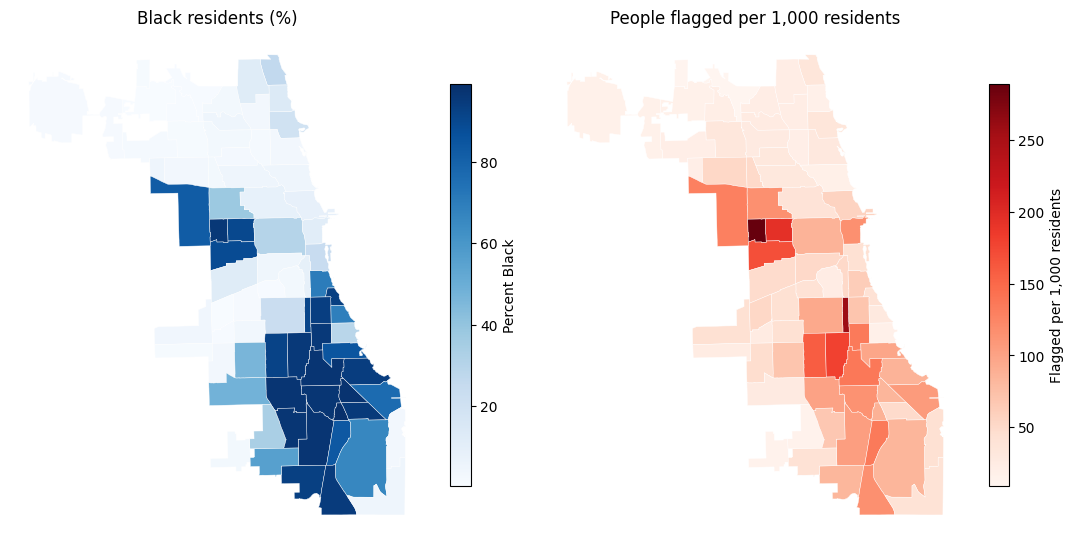

        community_area  pct_black  pct_low_income  flagged_per_1000
71  WEST GARFIELD PARK       95.6            53.8             289.1
25         FULLER PARK       91.3            56.2             258.3
19  EAST GARFIELD PARK       90.2            51.3             194.3
23           ENGLEWOOD       95.3            58.3             179.0
52      NORTH LAWNDALE       88.7            51.8             168.9


In [23]:
import geopandas as gpd

area_shapes = area_shapes_raw[["the_geom", "COMMUNITY"]].copy()
area_shapes["community_area"] = area_shapes["COMMUNITY"].str.strip().str.upper()
area_shapes = gpd.GeoDataFrame(area_shapes, geometry=gpd.GeoSeries.from_wkt(area_shapes["the_geom"]), crs="EPSG:4326")

area_map = area_shapes.merge(area_table, on="community_area", how="left")
if area_map["pct_black"].isna().any():
    print("Areas with no data on the map:", area_map.loc[area_map["pct_black"].isna(), "community_area"].tolist())

fig, axes = plt.subplots(1, 2, figsize=(11, 7))

area_map.plot(column="pct_black", cmap="Blues", linewidth=0.3, edgecolor="white", legend=True,
              legend_kwds={"label": "Percent Black", "shrink": 0.6}, ax=axes[0])
axes[0].set_title("Black residents (%)")

area_map.plot(column="flagged_per_1000", cmap="Reds", linewidth=0.3, edgecolor="white", legend=True,
              legend_kwds={"label": "Flagged per 1,000 residents", "shrink": 0.6}, ax=axes[1])
axes[1].set_title("People flagged per 1,000 residents")

for map_ax in axes:
    map_ax.set_axis_off()

plt.tight_layout()
fig.savefig(figures_dir / "fig3_map.png", dpi=200)
plt.show()

print(area_table.sort_values("flagged_per_1000", ascending=False)
      [["community_area", "pct_black", "pct_low_income", "flagged_per_1000"]].head(5).round(1))

## 8. Policing intensity and the list

### 8.1 Arrests and homicides by area

In [24]:
crimes_api = "https://data.cityofchicago.org/resource/ijzp-q8t2.json"

def fetch_counts(where_clause, label):
    cache_csv = raw_dir / f"crimes_{label}.csv"
    if cache_csv.exists():
        return pd.read_csv(cache_csv, dtype={"area_number": "Int64"})

    query_params = {
        "$select": "community_area, count(*) AS n",
        "$where": where_clause,
        "$group": "community_area",
        "$limit": 1000,
    }
    last_problem = None
    for attempt in range(1, 7):
        try:
            api_response = requests.get(crimes_api, params=query_params, timeout=120)
        except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as net_err:
            last_problem = str(net_err)
            time.sleep(10 * attempt)
            continue
        if api_response.status_code in retry_codes:
            last_problem = f"status {api_response.status_code}"
            time.sleep(10 * attempt)
            continue
        api_response.raise_for_status()
        try:
            count_rows = api_response.json()
        except ValueError:
            raise RuntimeError(f"Crimes API did not return JSON for {label}: {api_response.text[:300]}")
        counts = pd.DataFrame(count_rows)
        counts["area_number"] = pd.to_numeric(counts["community_area"], errors="coerce").astype("Int64")
        counts[label] = pd.to_numeric(counts["n"], errors="coerce")
        counts = counts.dropna(subset=["area_number"])[["area_number", label]]
        counts.to_csv(cache_csv, index=False)
        return counts
    raise RuntimeError(f"Crimes API failed for {label} after 6 tries ({last_problem})")

year_filter = "year between 2012 and 2016"
narcotic_counts = fetch_counts(f"{year_filter} AND arrest = true AND primary_type = 'NARCOTICS'", "narcotic_arrests_n")
all_arrest_counts = fetch_counts(f"{year_filter} AND arrest = true", "all_arrests_n")
homicide_counts = fetch_counts(f"{year_filter} AND primary_type = 'HOMICIDE'", "homicides_n")

policing = (
    area_names
    .merge(narcotic_counts, on="area_number", how="left")
    .merge(all_arrest_counts, on="area_number", how="left")
    .merge(homicide_counts, on="area_number", how="left")
    .fillna({"narcotic_arrests_n": 0, "all_arrests_n": 0, "homicides_n": 0})
)

feedback_table = area_table.merge(policing, on="community_area", how="inner")
for count_col, rate_col in [("narcotic_arrests_n", "narcotic_arrests_per_1000"),
                            ("all_arrests_n", "arrests_per_1000"),
                            ("homicides_n", "homicides_per_1000")]:
    feedback_table[rate_col] = feedback_table[count_col] / feedback_table["population"] * 1000

print(f"Areas: {len(feedback_table)}")
print(f"Narcotics arrests 2012 to 2016: {feedback_table['narcotic_arrests_n'].sum():,.0f}")
print(f"Homicides 2012 to 2016: {feedback_table['homicides_n'].sum():,.0f}\n")
print(feedback_table[["narcotic_arrests_per_1000", "arrests_per_1000", "homicides_per_1000", "flagged_per_1000"]].describe().round(1))

Areas: 77
Narcotics arrests 2012 to 2016: 135,307
Homicides 2012 to 2016: 2,667

       narcotic_arrests_per_1000  arrests_per_1000  homicides_per_1000  flagged_per_1000
count                       77.0              77.0                77.0              77.0
mean                        55.2             155.2                 1.1              65.9
std                         86.2             157.6                 1.3              55.6
min                          2.1              16.3                 0.0               9.2
25%                         11.8              52.1                 0.3              26.1
50%                         24.6              90.1                 0.6              44.1
75%                         71.7             215.1                 1.9              87.6
max                        555.3             871.8                 5.2             289.1


### 8.2 Does policing predict flagging beyond violence?

In [25]:
import statsmodels.formula.api as smf

feedback_model_data = feedback_table.assign(
    log_flagged=np.log1p(feedback_table["flagged_per_1000"]),
    log_narcotics=np.log1p(feedback_table["narcotic_arrests_per_1000"]),
    log_homicides=np.log1p(feedback_table["homicides_per_1000"]),
)

rate_cols = ["narcotic_arrests_per_1000", "homicides_per_1000", "flagged_per_1000"]
print("Spearman correlations")
print(feedback_table[rate_cols].corr(method="spearman").round(2), "\n")

for predictor_col in ["log_narcotics", "log_homicides"]:
    std_dev = feedback_model_data[predictor_col].std()
    feedback_model_data[f"z_{predictor_col}"] = (feedback_model_data[predictor_col] - feedback_model_data[predictor_col].mean()) / std_dev

homicide_only = smf.ols("log_flagged ~ z_log_homicides", data=feedback_model_data).fit(cov_type="HC3")
both_predictors = smf.ols("log_flagged ~ z_log_homicides + z_log_narcotics", data=feedback_model_data).fit(cov_type="HC3")

print(f"Homicides only:          R2 = {homicide_only.rsquared:.2f}")
print(f"Homicides + narcotics:   R2 = {both_predictors.rsquared:.2f}\n")
print(both_predictors.summary().tables[1])

Spearman correlations
                           narcotic_arrests_per_1000  homicides_per_1000  flagged_per_1000
narcotic_arrests_per_1000                       1.00                0.92              0.90
homicides_per_1000                              0.92                1.00              0.87
flagged_per_1000                                0.90                0.87              1.00 

Homicides only:          R2 = 0.79
Homicides + narcotics:   R2 = 0.85

                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           3.9120      0.036    110.100      0.000       3.842       3.982
z_log_homicides     0.2139      0.169      1.265      0.206      -0.118       0.545
z_log_narcotics     0.5055      0.163      3.104      0.002       0.186       0.825


### 8.3 Figure 4

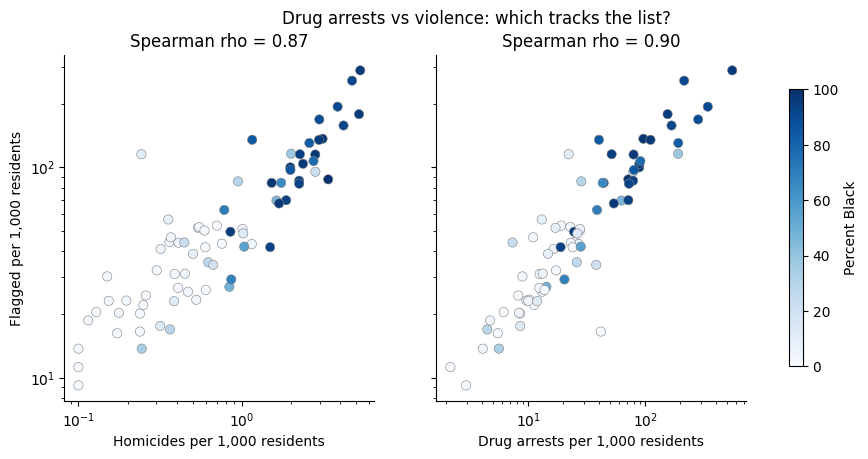

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

scatter_panels = [
    ("homicides_per_1000", "Homicides per 1,000 residents", axes[0]),
    ("narcotic_arrests_per_1000", "Drug arrests per 1,000 residents", axes[1]),
]

for x_col, x_label, panel_ax in scatter_panels:
    points = panel_ax.scatter(
        feedback_table[x_col] + 0.1, feedback_table["flagged_per_1000"],
        c=feedback_table["pct_black"], cmap="Blues", edgecolor="gray", linewidth=0.4, s=45, vmin=0, vmax=100,
    )
    panel_ax.set_xscale("log")
    panel_ax.set_yscale("log")
    panel_ax.set_xlabel(x_label)
    rho_value = feedback_table[[x_col, "flagged_per_1000"]].corr(method="spearman").iloc[0, 1]
    panel_ax.set_title(f"Spearman rho = {rho_value:.2f}")
    panel_ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Flagged per 1,000 residents")
fig.colorbar(points, ax=axes, label="Percent Black", shrink=0.8)
fig.suptitle("Drug arrests vs violence: which tracks the list?")
fig.savefig(figures_dir / "fig4_policing.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Testing Fixes

### 9.1 Fix A: remove police-based inputs

In [27]:
def disparity_report(score_values, label):
    scored = main_ssl.assign(test_score=score_values, test_flag=(score_values >= 250).astype(int))
    within_list = scored.groupby("race")["test_flag"].mean()
    flagged_counts = scored.groupby("race")["test_flag"].sum()
    city_rate = flagged_counts / (pd.Series(chicago_2010_share)[main_groups] * chicago_pop_2010) * 100
    return {
        "version": label,
        "flag_rate_black": within_list["Black"],
        "flag_rate_white": within_list["White"],
        "within_list_ratio": within_list["Black"] / within_list["White"],
        "city_per_100_black": city_rate["Black"],
        "city_per_100_white": city_rate["White"],
        "citywide_ratio": city_rate["Black"] / city_rate["White"],
        "rank_match_original": stats.spearmanr(score_values, main_ssl["ssl_score"]).statistic,
        "total_flagged": int(scored["test_flag"].sum()),
    }

fix_versions = {
    "No drug arrests or gang label": [col_name for col_name in feature_cols if col_name not in ("narcotic_arrests", "gang_affiliation")],
    "No police inputs at all": life_event_inputs,
}

fix_results = [disparity_report(main_ssl["ssl_score"].to_numpy(), "Original SSL")]

for version_label, version_cols in fix_versions.items():
    version_model = XGBRegressor(
        n_estimators=400, max_depth=6, learning_rate=0.1,
        tree_method="hist", n_jobs=-1, random_state=42,
    )
    version_model.fit(X_train[version_cols], y_train)
    version_scores = version_model.predict(main_ssl[version_cols])
    fix_results.append(disparity_report(version_scores, version_label))

fix_table = pd.DataFrame(fix_results).set_index("version")
print(fix_table.round(3).T)

version              Original SSL  No drug arrests or gang label  No police inputs at all
flag_rate_black             0.718                          0.737                    0.736
flag_rate_white             0.679                          0.706                    0.706
within_list_ratio           1.057                          1.044                    1.043
city_per_100_black         16.816                         17.269                   17.247
city_per_100_white          6.541                          6.801                    6.798
citywide_ratio              2.571                          2.539                    2.537
rank_match_original         1.000                          0.962                    0.952
total_flagged          282753.000                     292822.000               292554.000


### 9.2 Fix B: equal flag rates with fairlearn

In [28]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="fairlearn")

from xgboost import XGBClassifier
from fairlearn.postprocessing import ThresholdOptimizer

train_mask = race_train.isin(main_groups)
flag_train = (y_train >= 250).astype(int)

flag_classifier = XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.1,
    tree_method="hist", n_jobs=-1, random_state=42, eval_metric="logloss",
)
flag_classifier.fit(X_train[train_mask], flag_train[train_mask])

parity_optimizer = ThresholdOptimizer(
    estimator=flag_classifier,
    constraints="demographic_parity",
    objective="accuracy_score",
    predict_method="predict_proba",
    prefit=True,
)
parity_optimizer.fit(X_train[train_mask], flag_train[train_mask], sensitive_features=race_train[train_mask])

parity_flags = parity_optimizer.predict(main_ssl[feature_cols], sensitive_features=main_ssl["race"], random_state=42)

parity_scored = main_ssl.assign(parity_flag=parity_flags)
parity_within = parity_scored.groupby("race")["parity_flag"].mean()
parity_city = parity_scored.groupby("race")["parity_flag"].sum() / (pd.Series(chicago_2010_share)[main_groups] * chicago_pop_2010) * 100

print("Flag rate on the list with equal-rate thresholds")
print(parity_within.round(3), "\n")
print(f"Within-list ratio (Black/White): {parity_within['Black'] / parity_within['White']:.3f}")
print(f"City-wide ratio (Black/White):   {parity_city['Black'] / parity_city['White']:.3f}")
print(f"Agreement with original flags:   {(parity_flags == main_ssl['flag_250']).mean():.1%}\n")

entry_ratio = representation.loc["Black", "ratio"] / representation.loc["White", "ratio"]
original_within_ratio = race_summary.loc["Black", "flag_250_rate"] / race_summary.loc["White", "flag_250_rate"]
print(f"Entry ratio:                {entry_ratio:.2f}")
print(f"Original within-list ratio: {original_within_ratio:.2f}")
print(f"Entry x within-list:        {entry_ratio * original_within_ratio:.2f}  (compare to 2.57)")

Flag rate on the list with equal-rate thresholds
race
Black       0.735
Hispanic    0.736
White       0.736
Name: parity_flag, dtype: float64 

Within-list ratio (Black/White): 1.000
City-wide ratio (Black/White):   2.431
Agreement with original flags:   95.4%

Entry ratio:                2.43
Original within-list ratio: 1.06
Entry x within-list:        2.57  (compare to 2.57)


### 9.3 Fix C: change who enters the list, plus the final fix table

In [29]:
violent_entry = (
    (main_ssl["violent_arrests"] > 0)
    | (main_ssl["weapon_arrests"] > 0)
    | (main_ssl["victim_shooting"] > 0)
    | (main_ssl["victim_battery"] > 0)
)

entry_scored = main_ssl[violent_entry]
entry_flagged = entry_scored.groupby("race")["flag_250"].sum()
entry_city = entry_flagged / (pd.Series(chicago_2010_share)[main_groups] * chicago_pop_2010) * 100

print(f"People who stay on the list: {violent_entry.sum():,} of {len(main_ssl):,} ({violent_entry.mean():.1%})")
print(f"Share of list that is Black: {(entry_scored['race'] == 'Black').mean():.1%} (was {(main_ssl['race'] == 'Black').mean():.1%})\n")

fix_summary = pd.DataFrame([
    {"fix": "Original SSL", "changes": "nothing",
     "citywide_ratio": fix_table.loc["Original SSL", "citywide_ratio"], "total_flagged": fix_table.loc["Original SSL", "total_flagged"]},
    {"fix": "A1: drop drug arrests and gang label", "changes": "formula",
     "citywide_ratio": fix_table.loc["No drug arrests or gang label", "citywide_ratio"], "total_flagged": fix_table.loc["No drug arrests or gang label", "total_flagged"]},
    {"fix": "A2: drop all police inputs", "changes": "formula",
     "citywide_ratio": fix_table.loc["No police inputs at all", "citywide_ratio"], "total_flagged": fix_table.loc["No police inputs at all", "total_flagged"]},
    {"fix": "B: equal flag rates by race", "changes": "formula (uses race)",
     "citywide_ratio": parity_city["Black"] / parity_city["White"], "total_flagged": int(parity_flags.sum())},
    {"fix": "C: only enter people with violence on record", "changes": "who enters",
     "citywide_ratio": entry_city["Black"] / entry_city["White"], "total_flagged": int(entry_flagged.sum())},
])
fix_summary["citywide_ratio"] = fix_summary["citywide_ratio"].round(2)
print(fix_summary.to_string(index=False))

fix_summary.to_csv(figures_dir / "table3_fixes.csv", index=False)

People who stay on the list: 48,446 of 391,794 (12.4%)
Share of list that is Black: 74.4% (was 53.0%)

                                         fix             changes  citywide_ratio  total_flagged
                                Original SSL             nothing            2.57         282753
        A1: drop drug arrests and gang label             formula            2.54         292822
                  A2: drop all police inputs             formula            2.54         292554
                 B: equal flag rates by race formula (uses race)            2.43         288185
C: only enter people with violence on record          who enters            9.60          43661


### 9.4 Table 3: absolute burden by fix

In [30]:
city_population = pd.Series(chicago_2010_share)[main_groups] * chicago_pop_2010

per_100_values = {
    "Original SSL": (fix_table.loc["Original SSL", "city_per_100_black"], fix_table.loc["Original SSL", "city_per_100_white"]),
    "A1: drop drug arrests and gang label": (fix_table.loc["No drug arrests or gang label", "city_per_100_black"], fix_table.loc["No drug arrests or gang label", "city_per_100_white"]),
    "A2: drop all police inputs": (fix_table.loc["No police inputs at all", "city_per_100_black"], fix_table.loc["No police inputs at all", "city_per_100_white"]),
    "B: equal flag rates by race": (parity_city["Black"], parity_city["White"]),
    "C: only enter people with violence on record": (entry_city["Black"], entry_city["White"]),
}

fix_summary["black_per_100"] = fix_summary["fix"].map({fix_name: values[0] for fix_name, values in per_100_values.items()}).round(2)
fix_summary["white_per_100"] = fix_summary["fix"].map({fix_name: values[1] for fix_name, values in per_100_values.items()}).round(2)
fix_summary["black_flagged"] = (fix_summary["black_per_100"] / 100 * city_population["Black"]).round(0).astype(int)

table3_cols = ["fix", "changes", "black_per_100", "white_per_100", "citywide_ratio", "black_flagged", "total_flagged"]
print(fix_summary[table3_cols].to_string(index=False))

fix_summary[table3_cols].to_csv(figures_dir / "table3_fixes.csv", index=False)

                                         fix             changes  black_per_100  white_per_100  citywide_ratio  black_flagged  total_flagged
                                Original SSL             nothing          16.82           6.54            2.57         149168         282753
        A1: drop drug arrests and gang label             formula          17.27           6.80            2.54         153159         292822
                  A2: drop all police inputs             formula          17.25           6.80            2.54         152982         292554
                 B: equal flag rates by race formula (uses race)          17.23           7.09            2.43         152805         288185
C: only enter people with violence on record          who enters           3.68           0.38            9.60          32636          43661


## 10. Saved outputs

In [31]:
for saved_file in sorted(figures_dir.iterdir()):
    print(f"{saved_file.name:30s} {saved_file.stat().st_size / 1e3:8.1f} KB")

fig1_representation.png            46.1 KB
fig2_shap_gap.png                  74.7 KB
fig3_map.png                      196.7 KB
fig4_policing.png                 158.2 KB
table3_fixes.csv                    0.4 KB
